In [174]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections.abc import Callable
import matplotlib.ticker as ticker
import matplotlib.gridspec as gridspec
from scipy.linalg import eig, eigvals
import scipy.sparse.linalg as sc
from scipy.integrate import ode, solve_ivp
from scipy.interpolate import PchipInterpolator

In [185]:



def dip_norm(phir,phid):
    return 1-3*(np.cos(phir-phid))**2

def dip_first_der_norm(phir,phid):
    return -3*np.cos(phir)+15*np.cos(phir)*np.cos(phir-phid)**2-6*np.cos(phid)*np.cos(phir-phid)

def dip_second_der_norm(phir,phid):
    return -3+15*np.cos(phir-phid)**2-6*np.cos(phid)**2+\
        60*np.cos(phir)*np.cos(phid)*np.cos(phir-phid)+15*np.cos(phir)**2*(1-7*np.cos(phir-phid)**2)

def nom_der1(DelR,d):
    r = np.linalg.norm(DelR)
    rx = DelR[0]/r
    ry = DelR[1]/r
    
    f = -3*rx + 15*rx*(rx*d[0]+ry*d[1])**2-6*d[0]*(rx*d[0]+ry*d[1])
    return f/r**4

def nom_der1_vec(DelR,d):
    r = np.linalg.norm(DelR,axis=1)
    rx = DelR[:,0]/r
    ry = DelR[:,1]/r
    
    f = -3*rx + 15*rx*(rx*d[0]+ry*d[1])**2-6*d[0]*(rx*d[0]+ry*d[1])
    # return np.where(r>=a,0,f/r**4)
    return f/r**4

def dip_derivative_full_vec(Delta_R_vec: np.ndarray, d: np.ndarray,interaction_radius=None) -> float:
    Del_R = np.linalg.norm(Delta_R_vec,axis=1)
    i = j = 0
    rx = Delta_R_vec[:,0]
    ry = Delta_R_vec[:,1]
    # if Del_R==0:
    #     return 0
    # elif interaction_radius and Del_R > interaction_radius + 0.01:
    #     return 0
    potential = 0
    dot = (rx*d[0]+ry*d[1])
    if i == j:
        potential += 3/ Del_R**5-15*dot**2/Del_R**7
    potential += 6/ Del_R**5*d[0]**2
    potential -= 60*(d[0]*rx)*dot/Del_R**7
    potential -= 15*rx**2*(1/Del_R**7-7*dot**2/Del_R**9)
    return potential
    return np.where(Del_R>=a,0,potential)

def dip_derivative_ffull_vec(Delta_R_vec: np.ndarray, i:int, j:int, d: np.ndarray,interaction_radius=None) -> float:
    Del_R = np.linalg.norm(Delta_R_vec,axis=1)
   
    rx = Delta_R_vec[:,0]
    ry = Delta_R_vec[:,1]
    # if Del_R==0:
    #     return 0
    # elif interaction_radius and Del_R > interaction_radius + 0.01:
    #     return 0
    potential = 0
    dot = (rx*d[0]+ry*d[1])
    if i == j:
        potential += 3/ Del_R**5-15*dot**2/Del_R**7
    potential += 6/ Del_R**5*d[0]**2
    potential -= 60*(d[0]*rx)*dot/Del_R**7
    potential -= 15*rx**2*(1/Del_R**7-7*dot**2/Del_R**9)
    return potential

def dip_derivative_full(Delta_R_vec: np.ndarray, i: int, j: int, d: np.ndarray,interaction_radius=None) -> float:
    Del_R = np.linalg.norm(Delta_R_vec)

    # if Del_R==0:
    #     return 0
    # elif interaction_radius and Del_R > interaction_radius + 0.01:
    #     return 0
    potential = 0

    if i == j:
        potential += 3/ Del_R**5-15*np.dot(d,Delta_R_vec)**2/Del_R**7
    potential += 6/ Del_R**5*d[i]*d[j]
    potential -= 30*(d[i]*Delta_R_vec[j]+d[j]*Delta_R_vec[i])*np.dot(d,Delta_R_vec)/Del_R**7
    potential -= 15*Delta_R_vec[i]*Delta_R_vec[j]*(1/Del_R**7-7*np.dot(d,Delta_R_vec)**2/Del_R**9)
    # return Del_R
    return potential

def dip_dip(r_vec,d):
    r = np.linalg.norm(r_vec)
    if r==0:
        return 0
    potential = 1/r**3 * (1- 3*(np.dot(d,r_vec)/r)**2)
    return potential

def dip_dip_vec(r_vec,d):
    r = np.linalg.norm(r_vec,axis=0)

    potential = 1/r**3 * (1- 3*((d[0]*r_vec[0]+d[1]*r_vec[1])/r)**2)
    return potential


In [176]:
class TickProperties():
    
    major_xtick_step = 5,
    minor_xtick_step = 1
    major_ytick_step = 5
    minor_ytick_step = 1
    STRIP_OF_ZEROS_X = False
    STRIP_OF_ZEROS_Y = False

    def __init__(self,\
    xtick_step_major = 5,\
    xtick_step_minor = 1,\
    ytick_step_major = 5,\
    ytick_step_minor = 1,\
    SZX = False,\
    SZY = False):
        self.major_xtick_step = xtick_step_major
        self.minor_xtick_step = xtick_step_minor
        self.major_ytick_step = ytick_step_major
        self.minor_ytick_step = ytick_step_minor
        self.STRIP_OF_ZEROS_X = SZX
        self.STRIP_OF_ZEROS_Y = SZY

class Format():
    numb_xticks = None
    numb_yticks = None
    custom_func_x = None
    custom_func_y = None
    x_scale = None
    y_scale = None
    x_precion = "{:.2f}"
    y_precion = "{:.2f}"
    def __init__(self,numb_xticks=None,numb_yticks=None,custom_funx=None,custom_funy=None,xscale=None,yscale=None,xprec="{:.2f}",yprec="{:.2f}"):
        self.numb_xticks =numb_xticks
        self.numb_yticks = numb_yticks
        self.custom_func_x = custom_funx
        self.custom_func_y = custom_funy
        self.x_precion=xprec
        self.y_precion = yprec
        self.x_scale = xscale
        self.y_scale = yscale
    def formatx0(self,x,pos):
        try:
                # print(x,pos)#,"{:.2f}".format(w[int(x)]))
            # print(x,pos,self.numb_xticks)
            index = int((pos-1)*self.x_scale.shape[0]//self.numb_xticks)
            # print(index)
            # print(self.x_precion.format(self.x_scale[index]))
            return self.x_precion.format(self.x_scale[index])
        except:
            # print(self.x_precion.format(self.x_scale[-1]))
            return self.x_precion.format(self.x_scale[-1])
    def formatx1(self,x,pos):
        try:
                # print(x,pos)#,"{:.2f}".format(w[int(x)]))
            print(pos)
            index = int((pos)*self.x_scale.shape[0]//self.numb_xticks)
            # print(index)
            # print()
            return self.x_precion.format(self.x_scale[index])
        except:
            return self.x_precion.format(self.x_scale[-1])
    
    def formaty1(self,x,pos):
        try:
                # print(x,pos)#,"{:.2f}".format(w[int(x)]))

            index = int((pos-1)*self.y_scale.shape[0]//self.numb_yticks)
            # print(index)
            # print()
            return self.y_precion.format(self.y_scale[index])
        except:
            return self.y_precion.format(self.y_scale[-1])
        
    def formaty(self,x,pos):
        try:
            return self.y_precion.format(self.y_scale[int(x)])
        except:
            return ""

class Setup_Fig():
    DEFAULT_HEAT_EXTEND = (-0.5,39.5,29.5,-0.5)
    xlim = None
    ylim = None
    tickprop = TickProperties()
    formatter = Format()
    cm = 1/2.54 
    fig_width = 12*cm
    fig_height = 4.8/6.4*12*cm
    name_of_plot = None
    xax_share = None
    yax_share = None
    def __init__(self,name_of_plot = "sign_of_ev1.pdf",xlim=None,ylim=None,tickp=TickProperties(),formater=Format(),xax_share = False, yax_share = False,fig_width = 12*cm,fig_height = 4.8/6.4*12*cm):
        self.xlim=xlim
        self.ylim = ylim   
        self.tickprop =tickp       
        self.formatter = formater
        self.name_of_plot = name_of_plot
        self.xax_share = xax_share 
        self.yax_share = yax_share 
        self.fig_height = fig_height
        self.fig_width = fig_width


    
    plt.rcParams["lines.markersize"]=0.7
    plt.rcParams["axes.unicode_minus"]=True
    plt.rcParams["font.size"]=10
    plt.rcParams["text.usetex"]=True
    plt.rcParams["font.serif"]="Computer Modern Serif"
    plt.rcParams["text.latex.preamble"] = r"\usepackage{physics}\usepackage{amsmath}"

# ax.scatter(A,root,color='0')
    



    def return_fig(self,shape=(1,1),dots_per_inch=400,heightratio=None):
        if heightratio:
            fig, ax = plt.subplots(*shape,figsize=(self.fig_width,self.fig_height),dpi=dots_per_inch,sharex=self.xax_share,sharey=self.yax_share,height_ratios=heightratio)
        else:
            fig, ax = plt.subplots(*shape,figsize=(self.fig_width,self.fig_height),dpi=dots_per_inch,sharex=self.xax_share,sharey=self.yax_share)
        # trash, xw, yw, trash=self.DEFAULT_HEAT_EXTEND# im.get_extent()
        # self.formatter.numb_xticks = xw//self.tickprop.major_xtick_step
        # self.formatter.numb_yticks = yw//self.tickprop.major_ytick_step
        return fig, ax
    
    def return_gridspec(self,shape=(1,1),dots_per_inch=400):
        fig = plt.figure(figsize=(self.fig_width,self.fig_height),dpi=dots_per_inch)
        gs = gridspec.GridSpec(*shape, figure=fig)
        return fig, gs
        if shape[0]==1 or shape[1]==1:
            num = max(shape)
            axes = np.empty((num),dtype=object)
            for i in range(shape[0]):
                for j in range(shape[1]):
                    axes[i+j] = fig.add_subplot(gs[i,j])
        else:
            axes = np.empty(shape,dtype=object)
            # axes = []
            for i in range(shape[0]):
                for j in range(shape[1]):
                    axes[i,j] =  fig.add_subplot(gs[i,j])
                    # axes.append(fig.add_subplot(gs[i,j]))
                # axes[-1].set_aspect('auto')
        return fig, axes

        
    def format_ax(self,current_ax,shape,tickprop=None,j=0,bottom=True,set_ticks=True):
        # print(f"format_ax called with j={j}, shape={shape}")
        trash, xw, yw, trash=self.DEFAULT_HEAT_EXTEND# im.get_extent()
        self.formatter.numb_xticks = (xw+0.5)//self.tickprop.major_xtick_step
        self.formatter.numb_yticks = (yw+0.5)//self.tickprop.major_ytick_step
        pos= 'outer_left'
        current_ax.set_aspect('auto')
        if shape[1]>1:
                if j==0:
                    pos= 'outer_left'
                elif j<shape[1]-1 or j==-1:
                    pos = 'middle'
                elif j==shape[1]-1:
                    pos = 'outer_right'
                


        # axlimits have to be adapted
        # try:
        #     current_ax.set_xlim(*self.xlim)
        # except:
        #     pass
        # try:
        #     current_ax.set_ylim(*self.ylim)
        # except:
        #     pass    
    
        if set_ticks:
            if tickprop.STRIP_OF_ZEROS_X:
                current_ax.xaxis.set_major_formatter(ticker.FuncFormatter(self.formatter.formatx0))
            current_ax.yaxis.set_major_locator(ticker.MultipleLocator(tickprop.major_ytick_step))
            current_ax.yaxis.set_minor_locator(ticker.MultipleLocator(tickprop.minor_ytick_step))
            current_ax.xaxis.set_major_locator(ticker.MultipleLocator(tickprop.major_xtick_step))
            current_ax.xaxis.set_minor_locator(ticker.MultipleLocator(tickprop.minor_xtick_step))

            if tickprop.STRIP_OF_ZEROS_Y:
                current_ax.yaxis.set_major_formatter(ticker.FuncFormatter(self.formatter.formaty1))  

        if self.xax_share:
            
            if not bottom:
                current_ax.tick_params(axis='x',direction='in',which='both',bottom=True,top=True,labelbottom=False)
            else:
                current_ax.tick_params(axis='x',direction='in',which='both',bottom=True,top=True,labelbottom=True)
        else:
            current_ax.tick_params(axis='x',direction='in',which='both',bottom=True,top=True,labelbottom=True)

        if self.yax_share:    
            if pos=='outer_left':
                current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelleft=True)
            elif pos=='middle':
                current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelleft=False)
            elif pos=='outer_right':
                current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelright=True,labelleft=False)
            #     current_ax.yaxis.set_label_position("right")
                # current_ax.set_xlabel(r'$\Gamma \tilde{A}$')
                # current_ax.set_ylabel(r'$\tilde{y}$',rotation=0)
        
        else:    
            current_ax.tick_params(axis='y',direction='in',which='both',left=True,right=True,labelleft=True)   


        current_ax.tick_params(axis='both',which='major',length=4.5)
        plt.setp(current_ax.yaxis.get_majorticklabels(),va='center')
        
        return current_ax

In [177]:
from multiprocessing import Pool
from functools import partial

# def real_index(index,index_range,index_number,base):
#         real = []
        
#         for i in range(index_number-1):
#             if type(index_range[i]) is list:
#                 if not isinstance(index_range[i][0], int):
#                     raise ValueError("Index range must be a list of integers or a list of a tuple of integers.")
#                 projected_range = index_range[i][1] - index_range[i][0]
#             else:
#                 projected_range = index_range[i]
#             real.append(index//projected_range+base[i])
#             index = index-real[i]*projected_range
#         real.append(index+base[-1])
#         return real

def real_index(index,mat_range,index_number,base):
        real = np.zeros(index_number,dtype=np.int16)
        real[-1] = index%mat_range[-1]+base[-1]
        index = index//mat_range[-1]

        for i in range(1,index_number):
            real[-1-i] = index%mat_range[-1-i]+base[-1-i]
            index = index//mat_range[-1-i]
        # print(index)
        return real

def matrix_index(index,index_range,index_number):
        real = []
        
        for i in range(index_number-1):
            if type(index_range[i]) is list:
                if not isinstance(index_range[i][0], int):
                    raise ValueError("Index range must be a list of integers or a list of a tuple of integers.")
                projected_range = index_range[i][1] - index_range[i][0]
            else:
                projected_range = index_range[i]
            real.append(index//projected_range)
            index = index-real[i]*projected_range
        real.append(index)
        return real

def wrapper(function,mat_range,index_number,base,args,x):
        # print(args)
        # print(real_index(x,mat_range,index_number,base))
        return function(*real_index(x,mat_range,index_number,base),*args)

def total_range(index_range):
    """Calculate the total range based on the index range."""
    ranges = []
    bases = []
    tot_range = 1
    for i in index_range:
        if type(i) is list:
            if not isinstance(i[0], int):
                raise ValueError("Index range must be a list of integers or a list of a tuple of integers.")
            else:
                 tot_range *= i[1]-i[0]
                 ranges.append(i[1]-i[0])
                 bases.append(i[0])
        else:
            tot_range *= i
            ranges.append(i)
            bases.append(0)
    return tot_range, ranges, bases


def parallel_for(index_range,function,*args,chunk=1,core_number=4,sort_in_array=False):
    index_number = len(index_range)
    tot_range = 1
    tot_range, virtual_range, base = total_range(index_range)
    # print("index protperties: ",tot_range, virtual_range, base)
    
    return parallelizer(tot_range,function,index_range,index_number,virtual_range,base,chunk,core_number,sort_in_array,*args)

    

def parallelizer(i_range,function,index_range,index_number,mat_range,base,chunk,core_number,sort_in_array,*args):
    po = Pool(core_number)
    if not args:
         args=[0]
    # print(type(function))
    # print(mat_range)
    result = po.imap(partial(wrapper,function,mat_range,index_number,base,args),np.arange(i_range),chunksize=chunk)
    first_val = next(result)
    try:
         shape = first_val.shape
         out = np.zeros([*mat_range,*shape],dtype=type(first_val[0]))
    except:
         try:
            shape = [len(first_val)]
            if np.all(type(x)==type(first_val[0]) for x in first_val):
                out = np.zeros([*mat_range,*shape],dtype=type(first_val[0]))
            else:
                out = np.zeros([*mat_range,*shape],dtype=object)
         except:
              
              out = np.zeros([*mat_range],dtype=object)
    if sort_in_array:
        pass
    
    # out = np.zeros([*mat_range,*shape],dtype=object)
    # print('first value: ',first_val)
    out[*real_index(0,mat_range,index_number,np.zeros(index_number,dtype=np.int16))] = first_val
    for index, res in enumerate(result,start=1):
        # print(index,real_index(index,mat_range,index_number,np.zeros(index_number,dtype=np.int16)),res)
        out[*real_index(index,mat_range,index_number,np.zeros(index_number,dtype=np.int16))] = res
        # print(real_index(index,index_range,index_number),res)
    return out


def function(i,base):
    # j = i%2
    # i= i//2
    j=0
    print("func_arg",i,j,base)
    return i+base,j+base

def additional_wrap(i,j,base):
     i+=10
     j+=10
     return function(i,j,base)
# index_range = [3,3]

# parallel_for([[0,2],[-1,2]],function,chunk=1)
parallel_for([[0,2]],function,chunk=1,core_number=4)
# real_index(np.arange(9),[3,3],2,[0,0])

func_argfunc_arg 0 1  00  00



array([[0, 0],
       [1, 0]], dtype=int16)

In [178]:
def sort_eigenvalues(eigenvalues: np.ndarray,eigenvectors: np.ndarray, edge_size: int = 1) -> np.ndarray:
    """Sort eigenvalues in ascending order."""
    # eigenvectors *= np.conjugate(eigenvectors[0, :])/np.absolute(eigenvectors[0,:])#np.array([np.absolute(eigenvectors[0,i]) for i in range(eigenvectors.shape[1])]) # Normalize the eigenvectors
    comb = np.column_stack((eigenvalues.T, eigenvectors.T))
    # return comb
    # sorted_comb = sorted(comb, key=lambda x: x[0])
    # sorted_comb = sorted(comb, key=lambda x: np.abs(x[0]-120))
    # sorted_comb = sorted(comb, key=lambda x: max(np.max(np.abs(x[1:edge_size+1])),np.max(np.abs(x[-edge_size:]))),reverse=True)
    sorted_comb = sorted(comb, key=lambda x: max(np.sum(np.abs(x[1:edge_size+1])**2),np.sum(np.abs(x[-edge_size:])**2)),reverse=True)
    return np.array(sorted_comb)
def sort_eigenvalues_energies(eigenvalues: np.ndarray,eigenvectors: np.ndarray, energy: float = 0) -> np.ndarray:
    """Sort eigenvalues in ascending order."""
    # eigenvectors *= np.conjugate(eigenvectors[0, :])/np.absolute(eigenvectors[0,:])#np.array([np.absolute(eigenvectors[0,i]) for i in range(eigenvectors.shape[1])]) # Normalize the eigenvectors
    comb = np.column_stack((eigenvalues.T, eigenvectors.T))
    # return comb
    sorted_comb = sorted(comb, key=lambda x: x[0])
    # sorted_comb = sorted(comb, key=lambda x: np.abs(x[0]-energy))
    # sorted_comb = sorted(comb, key=lambda x: max(np.max(np.abs(x[1:edge_size+1])),np.max(np.abs(x[-edge_size:]))),reverse=True)
    # sorted_comb = sorted(comb, key=lambda x: max(np.sum(np.abs(x[1:edge_size+1])**2),np.sum(np.abs(x[-edge_size:])**2)),reverse=True)
    return np.array(sorted_comb)

def sort_eigenvalues_gap(eigenvalues: np.ndarray,eigenvectors: np.ndarray,cut: int = 4) -> np.ndarray:
    """Sort eigenvalues in ascending order."""
    gap = np.abs(eigenvalues[3:]-eigenvalues[2:-1])+np.abs(eigenvalues[1:-2]-eigenvalues[:-3])
    comb = np.column_stack((gap.T,eigenvalues[3:].T, eigenvectors[:,3:].T))
    
    sorted_comb = sorted(comb, key=lambda x: x[0])
    return np.array(sorted(sorted_comb[:cut],key=lambda x: x[1],reverse=True))



In [8]:
import scipy.constants as c

a0 = 4*np.pi*c.epsilon_0*c.hbar**2/(c.m_e*c.e**2)
d = np.array([1000,10000])*c.e*a0
r0 = np.array([3])/10**6
V = d**2/(4*np.pi*c.epsilon_0*r0**3)#*np.sqrt(c.hbar/2/m/w)**2
display(V/c.hbar)
m = 85.5*c.u
w = 2*np.pi*10**3*np.array([100,2000])
r= np.array([3,12])/10**6
np.sqrt(c.hbar/m/2/w)**2/r**2, np.sqrt(c.hbar/2/m/w)

array([2.26894795e+08, 2.26894795e+10])

(array([6.56762844e-05, 2.05238389e-07]),
 array([2.43122718e-08, 5.43638924e-09]))

-552.9599999999999 8.72803724096948
-165.72815184059726 10.737125675840087
10.876714746815958 13.319836701474236
68.16980108366482 16.662961941154958
75.87741615288857 21.012684423682003
67.08203932499364 26.681717757670675
54.78826254364981 34.034052732255496
43.3992138918854 43.3992138918854
34.034052732255525 54.78826254364976
26.681717757670697 67.08203932499362
21.012684423681968 75.87741615288849
16.662961941154958 68.16980108366498
13.319836701474236 10.876714746815958
10.737125675840105 -165.7281518405965
8.72803724096948 -552.9599999999998


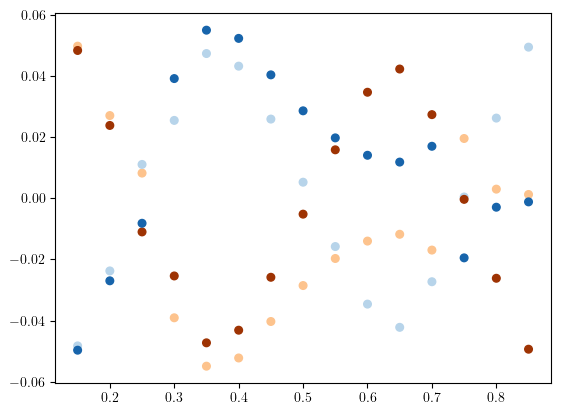

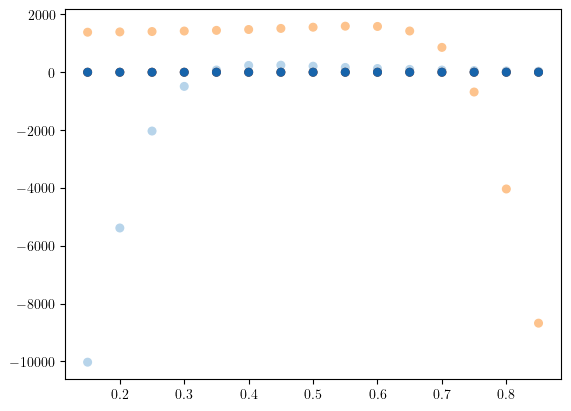

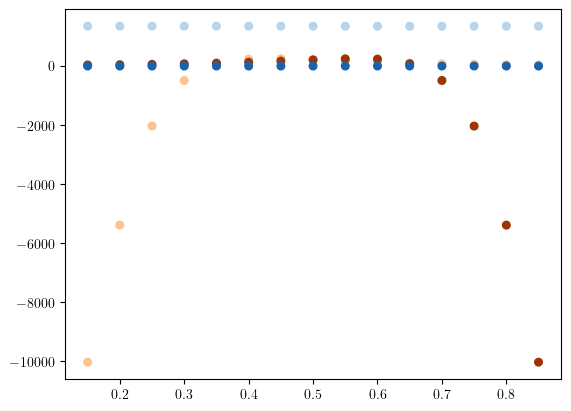

In [9]:
def grad(b,h,a,chain_length,interaction,d):
    latticeA = np.array([[0,0],[a,0]])
    latticeB = np.array([b,h])
    dist1 = latticeB-latticeA[0]
    dist2 = latticeA[1]-latticeB
    grad1 = interaction(dist1,d)
    grad2 = interaction(dist2,d)
    grad_vec = np.zeros(chain_length)
    print(grad1,grad2)
    grad_vec[0] = -grad1
    grad_vec[1:-1] = -grad2+grad1
    grad_vec[-1] = grad1-(grad1-grad2)*(chain_length%2)
    grad_vec[1:-1] *= (-1)**np.arange(chain_length-2)
    return grad_vec
    return grad1, grad2
    return dist1, dist2



def nearest_nb_Hamiltonian(b,h,a,chain_length,interaction,Delta,d):
    latticeA = np.zeros((2,chain_length//2+chain_length%2))
    latticeB = np.zeros((2,chain_length//2))
    for n in range(latticeA.shape[1]):
        latticeA[:,n] = n*np.array([1,0])*a
    for n in range(latticeB.shape[1]):
        latticeB[:,n] = n*np.array([1,0])*a + b * np.array([1,0])+h*np.array([0,1])
    dmat = np.zeros((chain_length,chain_length))
    ind = np.arange(chain_length,dtype=np.int16)
    inter_1 = interaction(latticeB[:,0]-latticeA[:,0],d)
    inter_2 = interaction(latticeB[:,0]-latticeA[:,1],d)
    dmat[ind[:-1:2],ind[1::2]]= inter_1
    dmat[ind[1::2],ind[:-1:2]]= inter_1
    dmat[ind[1:-1:2],ind[2::2]] = inter_2
    dmat[ind[2::2],ind[1:-1:2]] = inter_2
    dmat[0,0] = -inter_1
    dmat[-1,-1] = -inter_1-(inter_2-inter_1)*(chain_length%2)
    dmat[ind[1:-1],ind[1:-1]] = -inter_1-inter_2 

    # dmat[ind[2:-1:2],ind[2:-1:2]]= -Delta
    # print(inter_1,inter_2,b)
    return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]

def nearest_nb_Hamiltonian_test(alpha,b,h,a,chain_length,interaction,Delta,d):
    latticeA = np.zeros((2,chain_length//2+chain_length%2))
    latticeB = np.zeros((2,chain_length//2))
    for n in range(latticeA.shape[1]):
        latticeA[:,n] = n*np.array([1,0])*a
    for n in range(latticeB.shape[1]):
        latticeB[:,n] = n*np.array([1,0])*a + b * np.array([1,0])+h*np.array([0,1])
    dmat = np.zeros((chain_length,chain_length))
    ind = np.arange(chain_length,dtype=np.int16)
    inter_1 = interaction(latticeB[:,0]-latticeA[:,0],d)
    inter_2 = interaction(latticeB[:,0]-latticeA[:,1],d)
    dmat[ind[:-1:2],ind[1::2]]= inter_1
    dmat[ind[1::2],ind[:-1:2]]= inter_1
    dmat[ind[1:-1:2],ind[2::2]] = inter_2
    dmat[ind[2::2],ind[1:-1:2]] = inter_2
    dmat[0,0] = dmat[-1,-1] = alpha*np.max(np.abs(dmat))
    # dmat[0,0] = -inter_1
    # dmat[-1,-1] = -inter_1-(inter_2-inter_1)*(chain_length%2)
    # dmat[ind[1:-1],ind[1:-1]] = -inter_1-inter_2 


    # dmat[ind[2:-1:2],ind[2:-1:2]]= -Delta
    # print(inter_1,inter_2,b)
    return dmat #- np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]


import matplotlib.cm as cm
orange = cm.Oranges
blue = cm.Blues
chain_length = 4
N = 15
# b = np.linspace(0.465,0.535,N)
b = np.linspace(0.15,0.85,N)
h = 0.2
a = 1
# d = np.array([np.sqrt(1/3),np.sqrt(2/3)])
d = np.array([1,0])
eigenvecs = np.zeros((N,chain_length))
dist1 = np.zeros(N)
dist2 = np.zeros(N)
fig, ax = plt.subplots(1,1)
fig2, ax2 = plt.subplots(1,1)
fig3, ax3 = plt.subplots(1,1)
colors = np.zeros((chain_length,4))
colors[::2] = orange(np.linspace(0.3,0.9,chain_length//2+chain_length%2))
colors[1::2] = blue(np.linspace(0.3,0.8,chain_length//2))
for i in range(N):
    dmat = nearest_nb_Hamiltonian(b[i],h,a,chain_length,lambda x, y: dip_derivative_full(x, 0, 0, y),0,d)
    dmat += np.diag(np.ones(chain_length))*(m*w**2*r**2/V)[-1]
    beta = grad(b[i],h,a,chain_length,nom_der1,d)
    # eig, vecs = np.linalg.eig(dmat)
    # eigenvecs[i,:] = sorted(eig)
    eigenvecs[i,:] = np.linalg.solve(dmat,beta)
    # ax.scatter(b[i]*np.ones(chain_length-2),beta[::3],color='0')
    # ax.scatter(b[i]*np.ones(chain_length-2),eigenvecs[i,2:],color=colors[:2],s=30)
    ax.scatter(b[i]*np.ones(chain_length),eigenvecs[i,:],color=colors,s=30)
    # dist1[i], dist2[i] = grad(b[i],h,a,chain_length,nom_der1,d)
    # ax.scatter(b[i]*np.ones(chain_length),beta,color='0')
    ax2.scatter(b[i]*np.ones(chain_length),dmat[:,0],color=colors,s=30)
    ax3.scatter(b[i]*np.ones(chain_length),dmat[:,1],color=colors,s=30)
    # ax.scatter(b[i]*np.ones(1),dist1,color='0')
    # ax.scatter(b[i]*np.ones(1),dist2,color='red')
# ax.scatter(b,dist1,color='0')
# ax.scatter(b,dist2[::-1],color='red')
# ax.set_ylim(-3,3)
plt.show()


In [10]:
# long range
def grad_long_range(b,h,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T 
    indA = np.arange(latticeA.shape[0],dtype=np.int16)
    indB = np.arange(latticeB.shape[0],dtype=np.int16)
    grad_vec = np.zeros(chain_length)
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),-interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),-interaction(latticeB[i:]-latticeA[i],d)))
        grad_vec[2*i] = np.sum(interAA[i])+np.sum(interAB[i])
    
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),-interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),-interaction(latticeA[i+1:]-latticeB[i],d)))
        grad_vec[2*i+1] = np.sum(interBB[i])+np.sum(interBA[i])
    # print(interAA)
    # print(interAB)
    # print(interBB)
    # print(interBA)
    if cut:
        return np.where(np.abs(grad_vec)<cut,0,grad_vec)
    return grad_vec

def hopping_Ham2(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T 
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,2::2] = interAA[i]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,2::2] = interBB[i]
        dmat[2*i+1,1::2] = interBA[i]
        dmat[2*i+1,2*i+1] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    return dmat

def hopping_Ham(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat #- np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]

def hopping_Ham_alpha(b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )* alpha
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) * alpha
        
    dmat[0,0] = dmat[-1,-1] = alpha*dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]


def hopping_Ham_adapted(b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) 
        
    dmat[0,0] = dmat[-1,-1] = alpha+dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]


def hopping_Ham_adapted_quadratic(b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) 
        
    # dmat[0,0] = dmat[-1,-1] = alpha+dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    # return dmat - np.diag((np.arange(chain_length)-chain_length//2+0.5)**2*(dmat[0,0]-dmat[chain_length//2,chain_length//2])/(chain_length//2-0.5)**2+dmat[chain_length//2,chain_length//2])
    return dmat - np.diag(np.exp((np.arange(chain_length)-chain_length//2+0.5)**2)*(dmat[0,0]-dmat[chain_length//2,chain_length//2])/np.exp((chain_length//2-0.5)**2)+dmat[chain_length//2,chain_length//2])


def hopping_Ham_adapted_random(rand_vec,b,h,alpha,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = (- np.sum(interAA[i]) - np.sum(interAB[i]) )
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = (- np.sum(interBB[i]) - np.sum(interBA[i])) 
        
    dmat[0,0] = dmat[-1,-1] = dmat[chain_length//2,chain_length//2]#np.max(np.abs(dmat))0.3/alpha+
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    # return dmat - np.diag(np.ones(chain_length))*dmat[chain_length//2,chain_length//2]+np.diag(rand_vec/alpha)
    return dmat - np.diag(np.diag(dmat))+np.diag(rand_vec/alpha)

def hopping_Ham_block(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    lenA = latticeA.shape[0]
    lenB = latticeB.shape[0]
    # print("lattice",latticeA[0]-latticeA[:0])
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[:i],d),interaction(latticeA[i+1:]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[:i],d),interaction(latticeB[i:]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[i,:i] = interAA[i][:i]
        dmat[i,i+1:lenA] = interAA[i][i:]
        dmat[i,lenA:] = interAB[i]
        dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[:i],d),interaction(latticeB[i+1:]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[:i+1],d),interaction(latticeA[i+1:]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[lenA+i,lenA:lenA+i] = interBB[i][:i]
        dmat[lenA+i,lenA+i+1:] = interBB[i][i:]
        dmat[lenA+i,:lenA] = interBA[i]
        dmat[lenA+i,lenA+i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    
    if cut:
        return np.where(np.abs(dmat)<cut,0,dmat) #+ np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))
    return dmat# + np.diag(np.ones(chain_length)*np.max(np.abs(dmat)))




def hopping_Ham_xy(b,h,Delta,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham(b,h,Delta,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat

def hopping_Ham_xy_alpha(b,h,alpha,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_alpha(b,h,alpha,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham(b,h,0,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_alpha(b,h,alpha,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat

def hopping_Ham_xy_random(b,h,randvec,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_alpha(b,h,0,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham(b,h,0,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_alpha(b,h,0,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat+ np.diag(randvec)

def hopping_Ham_xy_block(b,h,Delta,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    for i in range(chain_length):
        dmat[2*i,::2] = Hamxx[i,:]
        dmat[2*i,1::2] = Hamxy[i,:]
        dmat[2*i+1,::2] = Hamxy[i,:]
        dmat[2*i+1,1::2] = Hamyy[i,:]
    return dmat

def hopping_Ham_xy_bblock(b,h,Delta,a,chain_length,interaction,d,*cut):
    Hamxx = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,0,d),d,*cut)
    Hamxy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,0,1,d),d,*cut)
    Hamyy = hopping_Ham_block(b,h,Delta,a,chain_length,lambda r,d:interaction(r,1,1,d),d,*cut)

    dmat = np.zeros((2*chain_length,2*chain_length))
    lenA = chain_length//2+chain_length%2
    lenB = chain_length//2
    dmat[:lenA,:lenA] = Hamxx[:lenA,:lenA]
    dmat[:lenA,lenA:2*lenA] = Hamxy[:lenA,:lenA]
    dmat[lenA:2*lenA,:lenA] = Hamxy[:lenA,:lenA]
    dmat[lenA:2*lenA,lenA:2*lenA] = Hamyy[:lenA,:lenA]
    dmat[:lenA,2*lenA:2*lenA+lenB] = Hamxx[:lenA,lenA:]
    dmat[:lenA,2*lenA+lenB:] = Hamxy[:lenA,lenA:]
    dmat[lenA:2*lenA,2*lenA:2*lenA+lenB] = Hamxy[:lenA,lenA:]
    dmat[lenA:2*lenA,2*lenA+lenB:] = Hamyy[:lenA,lenA:]

    dmat[2*lenA:2*lenA+lenB,:lenA] = Hamxx[lenA:,:lenA]
    dmat[2*lenA:2*lenA+lenB,lenA:2*lenA] = Hamxy[lenA:,:lenA]
    dmat[2*lenA:2*lenA+lenB,2*lenA:2*lenA+lenB] = Hamxx[lenA:,lenA:]
    dmat[2*lenA:2*lenA+lenB,2*lenA+lenB:] =  Hamxy[lenA:,lenA:]
    dmat[2*lenA+lenB:,:lenA] = Hamxy[lenA:,:lenA]
    dmat[2*lenA+lenB:,lenA:2*lenA] = Hamyy[lenA:,:lenA]
    dmat[2*lenA+lenB:,2*lenA:2*lenA+lenB] = Hamxy[lenA:,lenA:]
    dmat[2*lenA+lenB:,2*lenA+lenB:] = Hamyy[lenA:,lenA:]
    return dmat





def hopping_Ham_cut(b,h,Delta,a,chain_length,interaction,d,*cut):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((chain_length,chain_length))
    interAA = np.zeros((latticeA.shape[0],latticeA.shape[0]-1))
    interAB = np.zeros((latticeA.shape[0],latticeB.shape[0]))
    # print("lattice",latticeA[0]-latticeA[:0])
    def f(x):
        if x<0:
            return 0
        elif x>=chain_length:
            return chain_length
        else:
            return x
    for i in range(latticeA.shape[0]):
        interAA[i] = np.concatenate((interaction(latticeA[i]-latticeA[f(i-cut):i],d),interaction(latticeA[i+1:f(i+cut+1)]-latticeA[i],d)))
        interAB[i] = np.concatenate((interaction(latticeA[i]-latticeB[f(i-cut):i],d),interaction(latticeB[i:f(i+cut)]-latticeA[i],d)))
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        dmat[2*i,:2*i:2] = interAA[i][:i]
        dmat[2*i,2*(i+1)::2] = interAA[i][i:]
        dmat[2*i,1::2] = interAB[i]
        dmat[2*i,2*i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
        
    interBB = np.zeros((latticeB.shape[0],latticeB.shape[0]-1))
    interBA = np.zeros((latticeB.shape[0],latticeA.shape[0]))
    for i in range(latticeA.shape[0]):
        interBB[i] = np.concatenate((interaction(latticeB[i]-latticeB[f(i-cut):i],d),interaction(latticeB[i+1:f(i+cut+1)]-latticeB[i],d)))
        interBA[i] = np.concatenate((interaction(latticeB[i]-latticeA[f(i+1-cut):i+1],d),interaction(latticeA[i+1:f(i+1+cut)]-latticeB[i],d)))
        # dmat[latticeA.shape[0]+i,latticeA.shape[0]:] = interBB[i]
        # dmat[latticeA.shape[0]+i,:latticeA.shape[0]] = interBA[i]
        # dmat[i,i] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
        dmat[2*i+1,1:2*i+1:2] = interBB[i][:i]
        dmat[2*i+1,2*(i+1)+1::2] = interBB[i][i:]
        dmat[2*i+1,::2] = interBA[i]
        dmat[2*i+1,2*i+1] = - np.sum(interBB[i]) - np.sum(interBA[i]) + Delta
    return dmat

def hopping_Ham_k(k,b,h,Delta,a,chain_length,interaction,d):
    latticeA = np.stack((np.arange(chain_length//2+chain_length%2),np.zeros(chain_length//2+chain_length%2))).T * a
    latticeB = np.stack((np.arange(chain_length//2)*a+b,np.ones(chain_length//2)*h)).T  
    
    dmat = np.zeros((2,2),dtype=np.complex128)
    
    distAA = np.zeros((latticeA.shape[0]-1,2))
    distAB = np.zeros((latticeB.shape[0],2))
    # print("lattice",latticeA[0]-latticeA[:0])
    i = chain_length//4
    distAA = np.concatenate((-latticeA[:i]+latticeA[i],latticeA[i+1:]-latticeA[i]))
    interAA = interaction(distAA,d)
    distAB = np.concatenate((-latticeB[:i]+latticeA[i],latticeB[i:]-latticeA[i]))
    interAB = interaction(distAB,d)

    distBB = np.zeros((latticeB.shape[0]-1,2))
    distBA = np.zeros((latticeA.shape[0],2))
    
    distBB = np.concatenate((-latticeB[:i]+latticeB[i],latticeB[i+1:]-latticeB[i]))
    interBB = interaction(distBB,d)
    distBA = np.concatenate((-latticeA[:i+1]+latticeB[i],latticeA[i+1:]-latticeB[i]))
    interBA = interaction(distBA,d)
        # dmat[i,:latticeA.shape[0]] = interAA[i]
        # dmat[i,latticeA.shape[0]:] = interAB[i]
        # dmat[i,i] = - np.sum(interAA[i]) - np.sum(interAB[i]) + Delta
    cell_list = [n for n in range(chain_length//2)]
    
    unit_distAA = (np.array(cell_list[:i] +cell_list[i+1:])-i)*a
    unit_distAB = (np.array(cell_list)-i)*a
    dmat[0,0] = np.sum(interAA*np.exp(-1j*k*unit_distAA))
    dmat[0,1] = np.sum(interAB*np.exp(-1j*k*unit_distAB))
    dmat[0,0] += (- np.sum(interAA) - np.sum(interAB) + Delta)
    dmat[1,0] = np.sum(interBA*np.exp(-1j*k*unit_distAB))
    dmat[1,1] = np.sum(interBB*np.exp(-1j*k*unit_distAA))
    dmat[1,1] += (- np.sum(interBB) - np.sum(interBA) + Delta)

    return dmat

def BdG_Ham(b,h,Delta,a,chain_length,interaction,d):
    dmat_diag = hopping_Ham(b,h,Delta,a,chain_length,interaction,d)
    dmat_off = hopping_Ham(b,h,0,a,chain_length,interaction,d)
    dmat_BdG = np.zeros((2*chain_length,2*chain_length))
    dmat_BdG[:chain_length,:chain_length] = dmat_diag
    dmat_BdG[:chain_length,chain_length:] = dmat_off
    dmat_BdG[chain_length:,chain_length:] = -dmat_diag
    dmat_BdG[chain_length:,:chain_length] = -dmat_off
    return dmat_BdG

def BdG_Ham_k(k,b,h,Delta,a,chain_length,interaction,d):
    dmat_diag = hopping_Ham_k(k,b,h,Delta,a,chain_length,interaction,d)
    dmat_off = hopping_Ham_k(k,b,h,0,a,chain_length,interaction,d)
    dmat_BdG = np.zeros((4,4),dtype=np.complex128)
    dmat_BdG[:2,:2] = dmat_diag
    dmat_BdG[:2,2:4] = dmat_off
    dmat_BdG[2:4,:2] = -dmat_off
    dmat_BdG[2:4,2:4] = -dmat_diag
    
    return dmat_BdG

chain_length = 4
b0 = 0.3
h = 0.2
a=1
dmat = hopping_Ham(b0,h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x,y),d)
dmat_nn = nearest_nb_Hamiltonian(b0,h,a,chain_length,lambda x, y: dip_derivative_full(x,0,0,y),0,d)
# # # gradient_nn = grad(b,h,a,chain_length,nom_der1,d)
# # # gradient = grad_long_range(b,h,a,chain_length,nom_der1_vec,d)
# # # gradient, gradient_nn
dmat, dmat_nn

(array([[ 460.01805991, -489.42421291,   24.        ,    5.40615299],
        [-489.42421291,  389.42614917,   75.99806374,   24.        ],
        [  24.        ,   75.99806374,  389.42614917, -489.42421291],
        [   5.40615299,   24.        , -489.42421291,  460.01805991]]),
 array([[  75.99806374, -489.42421291,    0.        ,    0.        ],
        [-489.42421291,    0.        ,   75.99806374,    0.        ],
        [   0.        ,   75.99806374,    0.        , -489.42421291],
        [   0.        ,    0.        , -489.42421291,   75.99806374]]))

In [11]:
def del_grad_del_phi(R,angles):
    phi,theta = angles
    r = np.linalg.norm(R,axis=1)
    rx = R[:,0]/r
    ry = R[:,1]/r
   
    d = np.array([np.sin(theta)*np.cos(phi),np.sin(theta)*np.sin(phi)])
    dot1 = rx*d[0]+ry*d[1]
    dot2 = ry*d[0]-rx*d[1]
    return (30*(rx*ry*np.sin(theta)*np.cos(phi)-rx**2*np.sin(theta)*np.sin(phi)+6*np.sin(theta)*np.sin(phi))*dot1-6*np.sin(theta)*np.cos(phi)*dot2)/r**4
def del_grad_del_theta(R,angles):
    phi,theta = angles
    r = np.linalg.norm(R,axis=1)
    rx = R[:,0]/r
    ry = R[:,1]/r
    
    return (30*rx*np.sin(theta)*np.cos(theta)*(rx*np.cos(phi)+ry*np.sin(phi))**2-12*np.sin(theta)*np.cos(theta)*(rx*np.cos(phi)+ry*np.sin(phi)))/r**4

def jacobi(angles,b,h):
    phi,theta = angles
    R = np.array([b,h])
    return np.array([del_grad_del_phi(R,phi,theta),del_grad_del_theta(R,phi,theta)])
def full_jacobi(angles,b,h):
    phi,theta = angles
    d = np.array([np.sin(theta)*np.cos(phi),np.sin(theta)*np.sin(phi)])
    return np.array([np.sum(grad_long_range(b,h,a,chain_length,del_grad_del_phi,angles)*grad_long_range(b,h,a,chain_length,nom_der1_vec,d)),
                     np.sum(grad_long_range(b,h,a,chain_length,del_grad_del_theta,angles)*grad_long_range(b,h,a,chain_length,nom_der1_vec,d))])
a=1
def der1_angle(phi:float, theta:float,b:float,h:float) -> float:

    d = np.array([np.sin(theta)*np.cos(phi),np.sin(theta)*np.sin(phi),np.cos(theta)])
    r1 = np.array([b,h])
    r2 = np.array([b-a,h])
    return nom_der1(r1,d) + nom_der1(r2,d)
def full_grad(angles,b,h):
    phi,theta = angles
    d = np.array([np.sin(theta)*np.cos(phi),np.sin(theta)*np.sin(phi)])#,np.cos(theta)
    return np.sum(grad_long_range(b,h,a,chain_length,nom_der1_vec,d)**2)
from scipy.optimize import root_scalar, minimize
# print(der1_angle(0.9,0.3))
zero = root_scalar(der1_angle,x0=0,args=(np.pi/2,0.9,0.3))
chain_length = 10
full_jacobi([0,np.pi/2],0.9,0.3)
# minimize(full_grad,(0.935,np.pi/2),args=(0.9,0.3),jac=full_jacobi)
# minimize(lambda x : full_grad([x,np.pi/2],0.9,0.3),-1,jac=lambda y: full_jacobi([y,np.pi/2],0.9,0.3)[0] )
minimize(lambda x : full_grad([-9.348e-01,x],0.9,0.3),np.pi/2,jac=lambda y: full_jacobi([-9.348e-01,y],0.9,0.3)[1] )
# 

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 25.644732561228466
        x: [ 1.571e+00]
      nit: 0
      jac: [-3.209e-15]
 hess_inv: [[1]]
     nfev: 1
     njev: 1

In [12]:
np.pi/2

1.5707963267948966

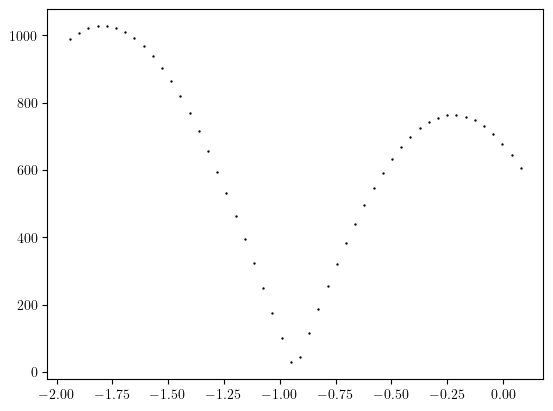

In [13]:
fig, ax = plt.subplots(1,1)
eps = 1.01
phi0 = -0.93
phis = np.linspace(phi0-eps,phi0+eps)
for i in range(len(phis)):
    ax.scatter(phis[i],np.sqrt(full_grad([phis[i],np.pi/2],0.9,0.3)),color="0")
plt.show()

In [45]:
import scipy.constants as c
import numpy as np
a0 = c.value("Bohr radius")#4*np.pi*c.epsilon_0*c.hbar**2/(c.m_e*c.e**2)
d = np.array([4426.805398225])*c.e*a0
r0 = np.array([10])/10**6
m = 88* c.u
w = 2*np.pi*1000*100
ratio = np.sqrt(c.hbar/2/m/w)**2/r0**2

V = d**2/(4*np.pi*c.epsilon_0*r0**3)#*np.sqrt(c.hbar/2/m/w)**2
V/c.h*ratio , V/c.h*np.sqrt(ratio), np.sqrt(ratio)
m*w**2*r0**2/V

array([455.6655406])

In [67]:
float(np.max(np.abs(beta))/np.max(np.abs(dmat))>0.05)

1.0

In [154]:
a=1
alpha = 1
b = np.linspace(0.35,0.65,N)
from scipy.optimize import minimize, minimize_scalar

def lstsq_min_vec(vec,A,b,alpha):
    return np.linalg.norm(A@vec-b)+alpha*np.linalg.norm(vec)

def abs_eigvec(param,b):
    phid = param[0]
    h = param[1]
    # h = -0.26
    d = np.array([np.cos(phid),np.sin(phid)])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    cut = 0.0#5455.6
    dmat = hopping_Ham(b,h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)
    beta = grad_long_range(b,h,a,chain_length,nom_der1_vec,d,cut)
    r1 = np.array([b,h])
    r2 = np.array([1,0])
    # eigenvecs = np.linalg.lstsq(dmat,beta)[0]
    # eigenvecs = minimize(lstsq_min_vec,args=(dmat,beta,1),x0=eigenvecs).x
    return np.max(np.abs(beta))/np.max(np.abs(dmat))*1000*float(np.max(np.abs(beta))/np.max(np.abs(dmat))>0.05)+np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))*alpha
    # return np.max(np.abs(eigenvecs))+np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))*alpha
# def wrap_minimize(l,base=0):

def abs_eigvec(param,b):
    phid = param[0]
    h = param[1]
    # h = -0.26
    d = np.array([np.cos(phid),np.sin(phid)])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    cut = 0.0#5455.6
    dmat = hopping_Ham(b,h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)
    beta = grad_long_range(b,h,a,chain_length,nom_der1_vec,d,cut)
    r1 = np.array([b,h])
    r2 = np.array([1,0])
    # eigenvecs = np.linalg.lstsq(dmat,beta)[0]
    # eigenvecs = minimize(lstsq_min_vec,args=(dmat,beta,1),x0=eigenvecs).x
    return np.max(np.abs(beta))/np.max(np.abs(dmat))*1000*float(np.max(np.abs(beta))/np.max(np.abs(dmat))>0.006)+np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))*alpha
   
N = 7
b = np.linspace(0.9,0.4,N)
# b = np.linspace(0.35,0.65,N)
phis = np.ones(N)*1#(np.pi/2)
hs = np.ones(N)*0.18
min_rder = np.zeros_like(b)
min_sub = np.zeros_like(b)
min_dis = np.zeros_like(b)
chain_length = 8
Deltap = 0.1
Deltah = 0.02
grid_numb = 7
otp_param = np.zeros([N,4])
for i in range(N):
    phi_grid = np.linspace(-Deltap,Deltap,grid_numb)+phis[i-1]
    h_grid = np.linspace(-Deltah,Deltah,grid_numb)+hs[i-1]
    min_vals = np.zeros((len(phi_grid),len(h_grid)))
    min_phi = np.zeros_like(min_vals)
    min_h = np.zeros_like(min_vals)
    min_vals = []
    min_phi = []
    min_h = []
    
    for n in range(len(phi_grid)):
        for m in range(len(h_grid)):
            # try:
                # res = minimize(abs_eigvec,x0=(phi_grid[n],h_grid[m]),args=b[i],bounds=((-2*np.pi,2*np.pi),(-0.7,0.7)),tol=1e-12)
                # print(abs_eigvec([0,0.3],0.4))
                res = minimize(abs_eigvec,x0=(phi_grid[n],h_grid[m]),args=b[i],bounds=((phis[i-1]-2*Deltap,phis[i-1]+2*Deltap),(hs[i-1]-2*Deltah,hs[i-1]+2*Deltah)),tol=1e-12)
                # res = minimize_scalar(abs_eigvec,args=b[i],bounds=(np.pi*0.35,np.pi*0.65),tol=1e-12)
                min_vals.append(res.fun)
                min_phi.append(res.x[0])
                # min_phi.append(res.x)
                min_h.append(res.x[1])
            # except:
            #     pass
    crit = np.array([min_vals, min_phi, min_h]).T
    # crit = np.array([min_vals, min_phi]).T
    sorted_crit = sorted(crit, key=lambda x: x[0])
    phis[i] = sorted_crit[0][1]
    hs[i] = sorted_crit[0][2]
    d = np.array([np.cos(phis[i]),np.sin(phis[i])])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    cut = 0.0#5
    dmat = hopping_Ham(b[i],hs[i],0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)
    beta = grad_long_range(b[i],hs[i],a,chain_length,nom_der1_vec,d,cut)
    r1 = np.array([b[i],hs[i]])
    r2 = np.array([1,0])
    # eigenvecs = np.linalg.lstsq(dmat,beta)[0]
    # eigenvecs = minimize(lstsq_min_vec,args=(dmat,beta,1),x0=eigenvecs).x
    min_rder[i] = np.max(np.abs(beta))/np.max(np.abs(dmat))
    min_sub[i] = np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))
    # min_dis[i] = np.linalg.norm(eigenvecs)
    # min_ratio[i] = sorted_crit[0][0]
    otp_param[i] = phis[i], hs[i], min_rder[i], min_sub[i]
    
    # print(1,end='')   
    # return np.stack((phis, hs))
chain_length = 8
# Deltas = np.linspace(0.1,250,20)
# Deltas = [0.1,80,170,250]
# Deltas = [2.5,0.8*250,4*250,2500]
# opt_param = parallel_for([[0,4]],wrap_minimize)
# wrap_minimize(0)

In [116]:
a=1
alpha = 1
b = np.linspace(0.35,0.65,N)
from scipy.optimize import minimize, minimize_scalar

def lstsq_min_vec(vec,A,b,alpha):
    return np.linalg.norm(A@vec-b)+alpha*np.linalg.norm(vec)

def abs_eigvec(param,b):
    phid = param[0]
    h = param[1]
    # h = -0.26
    d = np.array([np.cos(phid),np.sin(phid)])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    cut = 0.0#5455.6
    dmat = hopping_Ham(b,h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)
    beta = grad_long_range(b,h,a,chain_length,nom_der1_vec,d,cut)
    r1 = np.array([b,h])
    r2 = np.array([1,0])
    # eigenvecs = np.linalg.lstsq(dmat,beta)[0]
    # eigenvecs = minimize(lstsq_min_vec,args=(dmat,beta,1),x0=eigenvecs).x
    return np.max(np.abs(beta))/np.max(np.abs(dmat))*1000*float(np.max(np.abs(beta))/np.max(np.abs(dmat))>0.05)+np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))*alpha
    # return np.max(np.abs(eigenvecs))+np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))*alpha
# def wrap_minimize(l,base=0):
    
   
N = 20
# b = np.linspace(0.4,0.9,N)
b = np.linspace(0.9,0.4,N)
# b = np.linspace(0.35,0.65,N)
phis = np.ones(N)#*(np.pi/2)
hs = np.ones(N)*0.18#*-0.26
min_rder = np.zeros_like(b)
min_sub = np.zeros_like(b)
min_dis = np.zeros_like(b)
chain_length = 8
Deltap = 0.1#np.pi#
Deltah = 0.01#0.6#
grid_numb = 7
def wrap_min(i,trash=0):
    phi_grid = np.linspace(-Deltap,Deltap,grid_numb)
    h_grid = np.linspace(-Deltah,Deltah,grid_numb)
    min_vals = np.zeros((len(phi_grid),len(h_grid)))
    min_phi = np.zeros_like(min_vals)
    min_h = np.zeros_like(min_vals)
    min_vals = []
    min_phi = []
    min_h = []
    
    for n in range(len(phi_grid)):
        for m in range(len(h_grid)):
            # try:
                # res = minimize(abs_eigvec,x0=(phi_grid[n],h_grid[m]),args=b[i],bounds=((-2*np.pi,2*np.pi),(-0.7,0.7)),tol=1e-12)
                # print(abs_eigvec([0,0.3],0.4))
                res = minimize(abs_eigvec,x0=(phi_grid[n],h_grid[m]),args=b[i],bounds=((-2*Deltap,+2*Deltap),(-2*Deltah,2*Deltah)),tol=1e-12)
                # res = minimize_scalar(abs_eigvec,args=b[i],bounds=(np.pi*0.35,np.pi*0.65),tol=1e-12)
                min_vals.append(res.fun)
                min_phi.append(res.x[0])
                # min_phi.append(res.x)
                min_h.append(res.x[1])
            # except:
            #     pass
    crit = np.array([min_vals, min_phi, min_h]).T
    # crit = np.array([min_vals, min_phi]).T
    sorted_crit = sorted(crit, key=lambda x: x[0])
    phi = sorted_crit[0][1]
    h = sorted_crit[0][2]
    d = np.array([np.cos(phi),np.sin(phi)])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    cut = 0.0#5
    dmat = hopping_Ham(b[i],h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)
    beta = grad_long_range(b[i],h,a,chain_length,nom_der1_vec,d,cut)
    r1 = np.array([b[i],h])
    r2 = np.array([1,0])
    # eigenvecs = np.linalg.lstsq(dmat,beta)[0]
    # eigenvecs = minimize(lstsq_min_vec,args=(dmat,beta,1),x0=eigenvecs).x
    min_rder = np.max(np.abs(beta))/np.max(np.abs(dmat))
    min_sub = np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))
    # min_dis[i] = np.linalg.norm(eigenvecs)
    # min_ratio[i] = sorted_crit[0][0]
    return np.array([phi,h,min_rder,min_sub])

otp_param = parallel_for([[0,N]],wrap_min,core_number=18)
    # print(1,end='')   
    # return np.stack((phis, hs))
chain_length = 8
# Deltas = np.linspace(0.1,250,20)
# Deltas = [0.1,80,170,250]
# Deltas = [2.5,0.8*250,4*250,2500]
# opt_param = parallel_for([[0,4]],wrap_minimize)
# wrap_minimize(0)
# wrap_min(1)

In [ ]:
np.save("pure_phonon/tuning_1st_order0_smoother",otp_param)

In [105]:
def polynom(a,x):
    # return np.array([a[i]*x**i for i in range(len(a))])
    return np.sum(np.array([a[i]*x**i for i in range(len(a))]),axis=0)

In [106]:
# np.sum(polynom([1,2,4],2*np.arange(5)),axis=0)
polynom([1,2,4],2*np.arange(5))

array([  1,  21,  73, 157, 273])

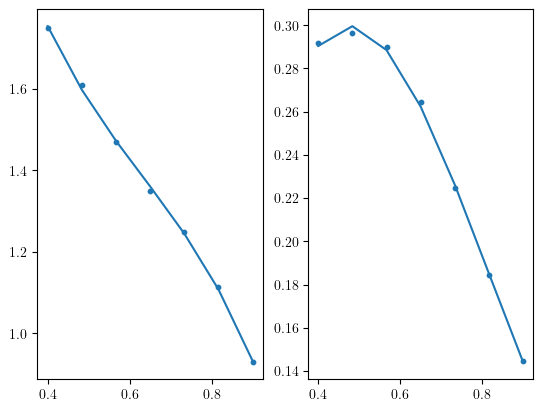

In [155]:
fig, ax = plt.subplots(1,2)
phi_sample = []
h_sample = []
Nc = 4
for i in range(otp_param.shape[0]):
    if (np.abs(otp_param[:,0])-np.where(np.abs(otp_param[:,0])/np.pi>1,1,0)*np.pi)[i]<1.8:
        phi_sample.append([b[i],(np.abs(otp_param[:,0])-np.where(np.abs(otp_param[:,0])/np.pi>1,1,0)*np.pi)[i]])
    if otp_param[i,1]>0.1:
        h_sample.append([b[i],otp_param[i,1]])
phi_sample = np.array(phi_sample)
h_sample = np.array(h_sample)
fit_phi = minimize(lambda a: np.sum((phi_sample[:,1]-polynom(a,phi_sample[:,0]))**2),x0=np.ones(Nc))
fit_h = minimize(lambda a: np.sum((h_sample[:,1]-polynom(a,h_sample[:,0]))**2),x0=np.ones(Nc))
coeff_phi = fit_phi.x
coeff_h = fit_h.x
# ax[0].scatter(b,np.abs(otp_param[:,0])-np.where(np.abs(otp_param[:,0])/np.pi>1,1,0)*np.pi,s=10)
# ax[1].scatter(b,np.abs(otp_param[:,1]),s=10)
# ax[0].scatter(b,np.abs(otp_param[:,2]),s=10)
# ax[1].scatter(b,np.abs(otp_param[:,3]),s=10)
ax[0].scatter(b,np.abs(otp_param[:,0]),s=10)
ax[1].scatter(b,np.abs(otp_param[:,1]),s=10)
ax[0].plot(b,polynom(coeff_phi,b))
ax[1].plot(b,polynom(coeff_h,b))
plt.show()

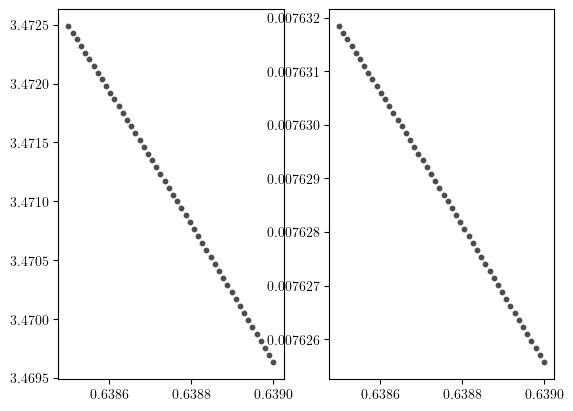

In [256]:
fig, ax = plt.subplots(1,2)
b2 = np.linspace(0.6385,0.639)
# b2 = np.linspace(0.5,0.9)
chain_length = 20
for i in range(len(b2)):
    phi = polynom(coeff_phi,b2[i])
    h = polynom(coeff_h,b2[i])
    d = np.array([np.cos(phi),np.sin(phi)])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    # cut = 0.0#5
    # dmat = hopping_Ham(b2[i],h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)hopping_Ham_alpha(b2[i],h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)+
    dmat = np.diag(np.ones(chain_length))*455
    beta = grad_long_range(b2[i],h,a,chain_length,nom_der1_vec,d,cut)
    r1 = np.array([b2[i],h])
    r3 = np.array([b2[i]-1,h])
    r2 = np.array([1,0])
    eigenvecs = np.linalg.lstsq(dmat,beta)[0]
    # eigenvecs = minimize(lstsq_min_vec,args=(dmat,beta,1),x0=eigenvecs).x
    min_rder = np.max(np.abs(beta))/np.max(np.abs(dmat))
    min_sub = np.abs(dip_derivative_full(Delta_R_vec=r2,d=d,i=0,j=0)/dip_derivative_full(Delta_R_vec=r1,d=d,i=0,j=0))
    # ax[0].scatter(b2[i],min_rder,color='0.3',s=10)
    # ax[1].scatter(b2[i],min_sub,color='0.3',s=10)
    # ax[0].scatter(b2[i],dip_derivative_full(r1,0,0,d)+dip_derivative_full(r3,0,0,d),color='0.3',s=10)
    # ax[0].scatter(b2[i],nom_der1(r1,d)-nom_der1(r3,d),color='0.3',s=10)
    ax[0].scatter(b2[i],np.max(np.abs(beta)),color='0.3',s=10)
    ax[1].scatter(b2[i],np.max(np.abs(eigenvecs)),color='0.3',s=10)
    # ax[0].scatter(b2[i],phi,color='0.3',s=10)
    # ax[1].scatter(b2[i],h,color='0.3',s=10)
plt.show()

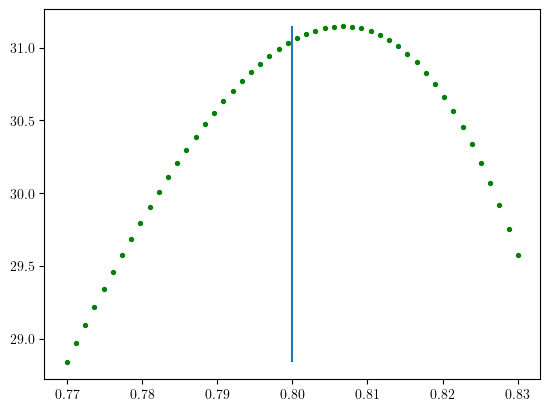

In [212]:
fig, ax = plt.subplots(1,1)
N = 50
a = 1
b2 = 0.8#0.6425
Delta = 0.03
x = np.linspace(b2-Delta,b2+Delta,N)
phi = polynom(coeff_phi,b2)
h = polynom(coeff_h,b2)
d = np.array([np.cos(phi),np.sin(phi)])
r1 = np.array([x,h*np.ones(N)])
r2 = np.array([1,0])
r3 = np.array([x-1,h*np.ones(N)])
# ax.scatter(b2[i],dip_derivative_full(r1,0,0,d),color="blue",s=8)
# ax.scatter(b2[i],dip_derivative_full(r2,0,0,d),color="orange",s=8)
# ax.scatter(b2[i],dip_derivative_full(r3,0,0,d),color="green",s=8)
y = dip_dip_vec(r3,d)+dip_dip_vec(r1,d)
# y = nom_der1_vec(r3.T,d)+nom_der1_vec(r1.T,d)
ax.scatter(x,y,color="green",s=8)
ax.vlines(b2,np.min(y),np.max(y))
plt.show()

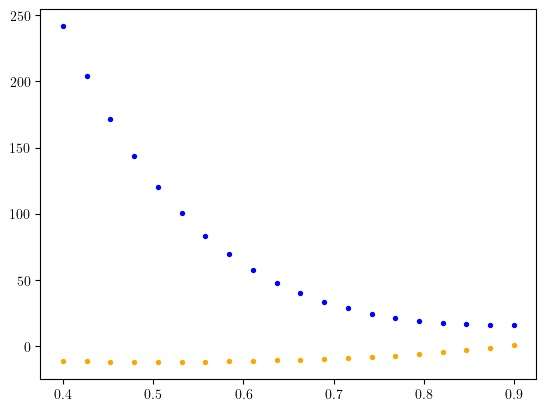

In [ ]:
fig, ax = plt.subplots(1,1)
b2 = np.linspace(0.4,0.9,20)
a = 1
for i in range(len(b2)):
    phi = polynom(coeff_phi,b2[i])
    h = polynom(coeff_h,b2[i])
    d = np.array([np.cos(phi),np.sin(phi)])
    r1 = np.array([b2[i],h])
    r2 = np.array([1,0])
    r3 = np.array([b2[i]-1,h])
    # ax.scatter(b2[i],dip_derivative_full(r1,0,0,d),color="blue",s=8)
    # ax.scatter(b2[i],dip_derivative_full(r2,0,0,d),color="orange",s=8)
    # ax.scatter(b2[i],dip_derivative_full(r3,0,0,d),color="green",s=8)
    ax.scatter(b2[i],dip_dip(r3,d)+dip_dip(r1,d),color="green",s=8)
plt.show()

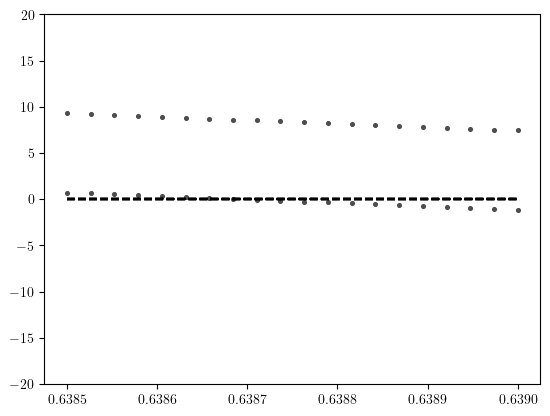

In [254]:
fig, ax = plt.subplots(1,1)
b2 = np.linspace(0.6385,0.639,20)
a = 1
chain_length = 20
for i in range(len(b2)):
    phi = polynom(coeff_phi,b2[i])
    h = polynom(coeff_h,b2[i])
    d = np.array([np.cos(phi),np.sin(phi)])
    # d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
    cut = 0.0#5
    dmat = hopping_Ham_alpha(b2[i],h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)+np.diag(np.ones(chain_length))*455
    eig, vec = np.linalg.eigh(dmat)
    ax.scatter(b2[i]*np.ones(chain_length),eig,color="0.3",s=7)
    ax.hlines(0,b2[0],b2[-1],color="0",linestyles="dashed")
    ylim = 20
    ax.set_ylim(-ylim,ylim)
plt.show()

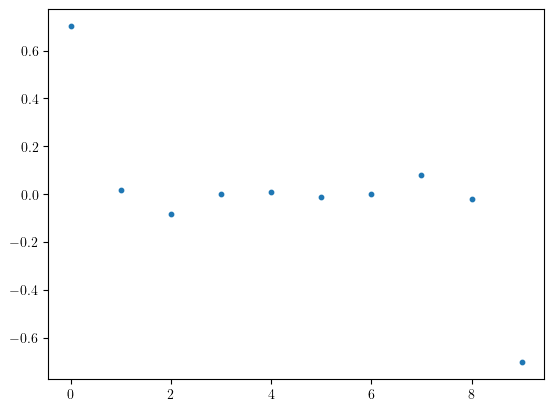

In [246]:
i = 3
phi = polynom(coeff_phi,b2[i])
h = polynom(coeff_h,b2[i])
d = np.array([np.cos(phi),np.sin(phi)])
# d = np.array([np.sqrt(1/3),np.sqrt(1/3)*np.sin(phid)])
cut = 0.0#5
dmat = hopping_Ham_alpha(b2[i],h,0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),d,cut)+np.diag(np.ones(chain_length))*455
eig, vec = np.linalg.eigh(dmat)
eigen = sort_eigenvalues_energies(eig,vec)
fig, ax = plt.subplots(1,1)
ax.scatter(np.arange(chain_length),eigen[4,1:],s=10)
plt.show()


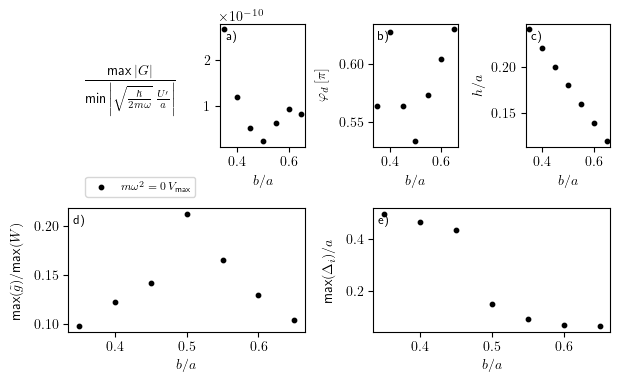

In [27]:
l =3
# N=20
# b = np.linspace(0.35,0.65,N)
cut = 0.05

setup = Setup_Fig(name_of_plot='lam2_anal_ml.png',fig_width=7,fig_height=4,xax_share=True)
fig = plt.figure(figsize=(setup.fig_width,setup.fig_height))
fig.tight_layout()
gs = gridspec.GridSpec(2,4, figure=fig)
ax0 = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])
ax2 = fig.add_subplot(gs[0,2])
ax3 = fig.add_subplot(gs[0,3])
ax4 = fig.add_subplot(gs[1,:2])
ax5 = fig.add_subplot(gs[1,2:])
# ax6 = fig.add_subplot(gs[1,8:])
# fig, ax = setup.return_fig((1,2))
# fig2, ax3 = setup.return_fig((1,2))
# N = 30
pad = 7
# b = np.linspace(0.25,0.75,N)
# b = np.linspace(0.3,0.7,N)
colors = ['0','indianred','green',"#162868ff"]
for l in range(1):
    phis_plot = phis
    hs_plot = hs
    max_dis = np.zeros(N)
    max_beta = np.zeros(N)
    max_dmat = np.zeros(N)
    for i in range(N):
        
        
        # dmat = hopping_Ham(b[i],hs[i],(m*w**2*r**2/V)[-1]/10**8,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),np.array([np.cos(phis[i]),np.sin(phis[i])]))
        dmat = hopping_Ham(b[i],hs_plot[i],0,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),np.array([np.cos(phis_plot[i]),np.sin(phis_plot[i])]),cut)
        # bdg = BdG_Ham(b[i],hs[i],(m*w**2*r**2/V)[-1]/10**8,a,chain_length,lambda x, y: dip_derivative_full_vec(x, y),np.array([np.cos(phis[i]),np.sin(phis[i])]))
        eig = np.linalg.eigvals(dmat)
        # ax1.scatter(b[i],np.max(np.abs(np.real(eig))),color='0',s=10)
        
        
        beta = grad_long_range(b[i],hs_plot[i],a,chain_length,nom_der1_vec,np.array([np.cos(phis_plot[i]),np.sin(phis_plot[i])]),cut)
        dis = np.linalg.solve(dmat,beta)
        h_new = beta-dmat@dis
        # ax3[1].scatter(b[i],np.max(h_new),color='0',s=10)
        # ax3[1].scatter(b[i]*np.ones(chain_length),beta,color='0',s=30)
        ax1.scatter(b[i],np.max(h_new)/(np.min(np.where(dmat==0,np.inf,np.abs(dmat)))*3/1000),color='0',s=10)
        # ax6.scatter(b[i],np.max(dis)*10**3,color='0',s=10)
        max_dis[i] = np.max(np.abs(np.real(dis)))
        max_beta[i] = np.max(beta)/np.max(np.abs(dmat))
    ax5.scatter(b,max_dis,color=colors[l],s=10)
    # ax5.scatter(b[i],np.max(beta),color='0',s=10)
    ax4.scatter(b,max_beta,color=colors[l],s=10,label=r"$m\omega^2 ={}\,$".format(0)+r"$V_\text{max}$")
        # ax4.scatter(b[i],np.max(np.abs(dmat)),color='0',s=10)
        # ax4.scatter(b[i],np.max(beta)/np.min(np.where(dmat==0,np.inf,np.abs(dmat))),color='0',s=10)
        # ax2.scatter(b[i],sorted_crit[0][0],color='0',s=10)
    if l==0:
        ax2.scatter(b,np.abs(phis_plot/np.pi),color='0',s=10)
        ax3.scatter(b,np.abs(hs_plot),color='0',s=10)
ax0.axis("off")
ax4.legend(fontsize=8,bbox_to_anchor=(0.05, 1.05))
ax1.set_xlabel(r"$b/a$")
ax2.set_ylabel(r"$\varphi_d\,[\pi]$",labelpad=pad)
ax2.set_xlabel(r"$b/a$")
ax3.set_ylabel(r"$h/a$")
ax3.set_xlabel(r"$b/a$")
ax4.set_xlabel(r"$b/a$")
# ax1.text(0.7,0.7,"a)",fontsize=9)

ax5.set_ylabel(r"max$(\Delta_i)/a$",labelpad=pad)
ax0.text(0.2,0.5,r"$$\frac{\text{max}\left|G\right|}{\text{min}\left|\sqrt{\frac{\hbar }{2m \omega}}\,\frac{{U}'}{a}\right|}$$")
ax5.set_xlabel(r"$b/a$")
ax4.set_ylabel(r"$\text{max}(\tilde{g})/\text{max}(W)$",labelpad=pad)
# ax6.set_xlabel(r"$b/a$")
# ax6.set_ylabel(r"$$\text{max}(\Delta_i)/\sqrt{\hbar/2m\omega}$$",labelpad=pad)
ax4.text(0.02,0.88,"d)",fontsize=9,transform=ax4.transAxes)
ax5.text(0.02,0.88,"e)",fontsize=9,transform=ax5.transAxes)
ax1.text(0.06,0.87,"a)",fontsize=9,transform=ax1.transAxes)
ax2.text(0.06,0.87,"b)",fontsize=9,transform=ax2.transAxes)
ax3.text(0.06,0.87,"c)",fontsize=9,transform=ax3.transAxes)
plt.subplots_adjust(wspace=0.8,hspace=0.5)
# plt.savefig("/home//christian/Documents/master/protocol/pictures/"+"tuning_first_order_to_zero4.pdf",bbox_inches='tight')#free_evol_1spto10coupling
plt.show()

In [20]:
A = np.reshape(np.arange(9),(3,3))
A = np.diag(np.ones(3))
b = np.arange(3)
np.linalg.lstsq(A,b)[0]

array([0., 1., 2.])